# Исследовательский анализ рынка общественного питания в Москве

- Автор: Дегтярёва Александра
- Дата:18.11.2025

### Цели и задачи проекта

**Цель:** Провести исследовательский анализ рынка общественного питания в Москве

**Задачи:**
1. Загрузить данные и познакомиться с их содержимым
2. Провести предобработку данных
3. Провести исследовательский анализ данных
4. Сформулировать выводы по проведённому анализу

### Описание данных

**Датасет** `rest_info`

- `name` — название заведения
- `address` — адрес заведения
- `district` — административный район, в котором находится заведение, например Центральный административный округ
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0)
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки) 0 — заведение не является сетевым, 1 — заведение является сетевым.
- `seats` — количество посадочных мест


**Датасет** `rest_price`
- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — хранит среднюю стоимость заказа в виде диапазона (например «Средний счёт: 1000–1500 ₽» )
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»: (Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений. Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число. Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт)
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»: (Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений. Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число. Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.)

### Содержимое проекта
1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговые выводы.

## 1. Загрузка данных и знакомство с ними

- Загрузите данные о заведениях общественного питания Москвы. Путь к файлам: `/datasets/rest_info.csv` и `/datasets/rest_price.csv`.

In [1]:
!pip install phik
# Импортируем библиотеки
import pandas as pd
import numpy as np

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [2]:
df_info = pd.read_csv('/datasets/rest_info.csv')
df_price = pd.read_csv('/datasets/rest_price.csv')

In [3]:
df_info.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [4]:
df_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [5]:
df_price.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [6]:
df_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


---

### Промежуточный вывод

**df_info** содержит 9 столбцов и 8406 строк

Пропуски содержатся в `hours` и `seats` (вероятно из-за особенности сбора данных)

В основном типы данных используются верные, но можно оптимизировать кол-во занимаемой памяти у `rating`, `chain` и `seats`
Поменять тип у `category` и `district` с object на category, заменить у `seats` с float на int (кол-во мест не может быть дробным)

По названиям столбцов все хорошо

**df_price** содержит 5 столбцов и 4058 строк

Небольшое количество пропусков содержатся во всех стоблцах кроме `id` 

Тип у `price` можно поменять на category, у `middle_avg_bill` и `middle_coffee_cup` можно уменьшить размерность

По названиям столбцов все хорошо

In [7]:
df = df_info.merge(df_price, on = 'id', how = 'left')
# приняли решение соединять по left чтобы не потерять данные, пропуски заменим индикаторами

In [8]:
# смотрим результат
df.info()

# запоминаем кол-во строк
initial_rows = len(df)

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


In [9]:
# Комментарий ревьюера
# создаем копию датасета до преобразования для возможности проверить сделанные изменения после предобработки
# только не надо эту копию потом использовать в проекте
temp = df.copy() 
len(temp)

8406

## 2. Предобработка данных

Нужно оптимизировать кол-во занимаемой памяти у `rating`, `chain` и `seats`
Поменять тип у `category` и `district` с object на category, заменить у `seats` с float на int (кол-во мест не может быть дробным)

Тип у `price` можно поменять на category, у `middle_avg_bill` и `middle_coffee_cup` можно уменьшить размерность

In [10]:
# меняем тип данных с учетом пропусков и памяти
conversions = {
    'rating': 'float16',
    'chain': 'Int8', 
    'seats': 'float16',
    'middle_avg_bill': 'float16',
    'middle_coffee_cup': 'float16'
}

for column, dtype in conversions.items():
    df[column] = pd.to_numeric(df[column]).astype(dtype)
    
category_columns_ctg = ['category','district']
df[category_columns_ctg] = df[category_columns_ctg].astype('category')

In [11]:
# проверяем и видим что кол-во используемой памяти существенно сократилось
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   id                 8406 non-null   object  
 1   name               8406 non-null   object  
 2   category           8406 non-null   category
 3   address            8406 non-null   object  
 4   district           8406 non-null   category
 5   hours              7870 non-null   object  
 6   rating             8406 non-null   float16 
 7   chain              8406 non-null   Int8    
 8   seats              4795 non-null   float16 
 9   price              3315 non-null   object  
 10  avg_bill           3816 non-null   object  
 11  middle_avg_bill    3149 non-null   float16 
 12  middle_coffee_cup  535 non-null    float16 
dtypes: Int8(1), category(2), float16(4), object(6)
memory usage: 558.9+ KB


- Изучите пропущенные значения в данных: посчитайте их количество в каждом столбце датафрейме, изучите данные с пропущенными значениями и предположите гипотезы их появления. Проведите обработку пропущенных значений: вы можете заменить пропуски на определённое значение, удалить строки с пропусками или оставить их как есть.

In [12]:
# кол-во строк с пропусками
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [13]:
# считаем % строк с пропусками
round(df.isna().sum() / len(df) * 100 , 2)

id                    0.00
name                  0.00
category              0.00
address               0.00
district              0.00
hours                 6.38
rating                0.00
chain                 0.00
seats                42.96
price                60.56
avg_bill             54.60
middle_avg_bill      62.54
middle_coffee_cup    93.64
dtype: float64

In [14]:
# Комментарий ревьюера
def show_missing_stats(tmp0):
    """
    Функция для отображения статистики пропущенных значений в DataFrame.
    """
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': tmp0.isnull().sum(),
        'Доля пропусков': tmp0.isnull().mean()
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
    
    if missing_stats.empty:
        return "Пропусков в данных нет"
    
    # Форматируем при выводе через Styler
    return (missing_stats.style.format({'Доля пропусков': '{:.4f}'}).background_gradient(cmap='coolwarm'))
show_missing_stats(df)

,Кол-во пропусков,Доля пропусков
hours,536,0.0638
seats,3611,0.4296
price,5091,0.6056
avg_bill,4590,0.5460
middle_avg_bill,5257,0.6254
middle_coffee_cup,7871,0.9364


**Пропуски**

Небольшое количество пропусков содержится в `hours`, вероятно, просто не указаны часы работы. Можно добавить индикатор

Большое количество пропусков у `seats`, `price`, `avg_bill`, `middle_avg_bill`  тоже скорее всего просто не указанная информация без возможного восстановления. В качестве решения - индикатор

Наибольшее кол-во пропусков у `middle_coffee_cup` - 93%. Этот стоблец зависит от `avg_bill` в котором тоже содержится большое кол-во пропусков. Восстановить данные на основе других столбцов не получится поэтому предполагаю использование индикатора


In [15]:
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.000000,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.500000,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.601562,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.000000,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.000000,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


In [16]:
# заменяем пустые значения индикатором -1 (кол-во посадочных мест не может быть -1 как и все остальное)
df['seats'] =df['seats'].fillna(-1)
df['price'] =df['price'].fillna(-1)
df['hours'] =df['hours'].fillna(-1)
df['avg_bill'] =df['avg_bill'].fillna(-1)
df['middle_avg_bill'] =df['middle_avg_bill'].fillna(-1)
df['middle_coffee_cup'] =df['middle_coffee_cup'].fillna(-1)

# после заполнения пропусков меняем тип у price
df['price'] = df['price'].astype('category')

In [17]:
# Комментарий ревьюера
# Проверим сколько удалено строк датасета
a, b = len(temp), len(df)
print(a, b, round((a-b)/a*100, 2))

8406 8406 0.0


In [18]:
df.info()
# все пропуски заполнены

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   id                 8406 non-null   object  
 1   name               8406 non-null   object  
 2   category           8406 non-null   category
 3   address            8406 non-null   object  
 4   district           8406 non-null   category
 5   hours              8406 non-null   object  
 6   rating             8406 non-null   float16 
 7   chain              8406 non-null   Int8    
 8   seats              8406 non-null   float16 
 9   price              8406 non-null   category
 10  avg_bill           8406 non-null   object  
 11  middle_avg_bill    8406 non-null   float16 
 12  middle_coffee_cup  8406 non-null   float16 
dtypes: Int8(1), category(3), float16(4), object(5)
memory usage: 501.7+ KB


In [19]:
# смотрим на наличие неявнях дубликатов
for column in ['category','district','price']:
    print(f'Уникальные значения в столбце {column}:')
    print(df[column].sort_values().unique())
    print()

Уникальные значения в столбце category:
['бар,паб', 'булочная', 'быстрое питание', 'кафе', 'кофейня', 'пиццерия', 'ресторан', 'столовая']
Categories (8, object): ['бар,паб', 'булочная', 'быстрое питание', 'кафе', 'кофейня', 'пиццерия', 'ресторан', 'столовая']

Уникальные значения в столбце district:
['Восточный административный округ', 'Западный административный округ', 'Северный административный округ', 'Северо-Восточный административный округ', 'Северо-Западный административный округ', 'Центральный административный округ', 'Юго-Восточный административный округ', 'Юго-Западный административный округ', 'Южный административный округ']
Categories (9, object): ['Восточный административный округ', 'Западный административный округ', 'Северный административный округ', 'Северо-Восточный административный округ', ..., 'Центральный административный округ', 'Юго-Восточный административный округ', 'Юго-Западный административный округ', 'Южный административный округ']

Уникальные значения в столбце

In [20]:
# проверяем полные дубликаты 
df.duplicated().sum()

0

In [21]:
# проверяем дубликаты по id 
df.duplicated(subset='id').sum()

0

Дубликаты не обнаружены

In [22]:
# приводим к нижнему регистру и убираем пробелы
df['name'] = df['name'].str.lower().str.strip()
df['address'] = df['address'].str.lower().str.strip()

# считаем количество дубликатов по name и address
num_duplicates = df.duplicated(subset=['name', 'address']).sum()

print(f'Количество неявных дубликатов: {num_duplicates}')

Количество неявных дубликатов: 4


Есть 4 неявнях дубликата, удалим их

In [23]:
df = df.drop_duplicates(subset=['name', 'address'])

In [24]:
df['is_24_7'] = df['hours'] == 'ежедневно, круглосуточно'

In [25]:
# Комментарий рев
df['is_24_7'].value_counts()

False    7672
True      730
Name: is_24_7, dtype: int64

In [26]:
cleaned_rows = len(df)
deleted_rows_absolute = initial_rows - cleaned_rows
deleted_rows_relative = (deleted_rows_absolute / initial_rows) * 100

print("Результаты очистки данных: ")
print(f"Исходное количество строк: {initial_rows}")
print(f"Количество строк после очистки: {cleaned_rows}")
print(f"Удалено строк (абсолютное значение): {deleted_rows_absolute}")
print(f"Удалено строк (относительное значение): {deleted_rows_relative:.2f}%")

Результаты очистки данных: 
Исходное количество строк: 8406
Количество строк после очистки: 8402
Удалено строк (абсолютное значение): 4
Удалено строк (относительное значение): 0.05%


In [27]:
# Комментарий ревьюера
# Проверим сколько удалено строк датасета
a, b = len(temp), len(df)
print(" Было строк в исходном датасете", a,
      '\n', "Осталось строк в датасете после обработки", b,
      '\n', "Удалено строк в датасете после обработки", a-b,
      '\n', "Процент потерь", round((a-b)/a*100, 2))

 Было строк в исходном датасете 8406 
 Осталось строк в датасете после обработки 8402 
 Удалено строк в датасете после обработки 4 
 Процент потерь 0.05


### Промежуточный вывод

После предобработки данных напишите промежуточный вывод о проведённой работе. Отразите количество или долю отфильтрованных данных, если вы что-то удаляли.

**Выводы**

1. Было проведено знакомство с данными
2. Проверили данные на явные и неявные дубликаты (обнаружили небольшое уоличество дубликатов)
3. Поработали с пропусками (заменили пропуски на индикаторы)
4. Общее количество данных уменьшилось на 0,05%
5. Добавили новый стоблец

## 3. Исследовательский анализ данных
Проведите исследовательский анализ исходных данных.

При исследовании данных используйте визуализации. Проверьте, что для каждого случая подобран оптимальный тип визуализации с корректным оформлением. У графика должен быть заголовок, понятные подписи по осям, при необходимости легенда, а его размер является оптимальным для изучения.

После исследования каждого пункта оставляйте небольшой комментарий с выводом или обсуждением результата. В конце шага обобщите результаты, выделив, по вашему мнению, самые важные.

---

### Задача 1

Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по каждой категории. Результат сопроводите подходящей визуализацией.

In [28]:
# проверяем распределение данных по значениям столбца category
print('Распределение данных столбца category:')
df['category'].value_counts()

Распределение данных столбца category:


кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

In [29]:
# проверяем распределение данных по значениям столбца category
print('Распределение данных столбца category:')
df['category'].value_counts(normalize=True)

Распределение данных столбца category:


кафе               0.282790
ресторан           0.243037
кофейня            0.168174
бар,паб            0.090931
пиццерия           0.075339
быстрое питание    0.071769
столовая           0.037491
булочная           0.030469
Name: category, dtype: float64

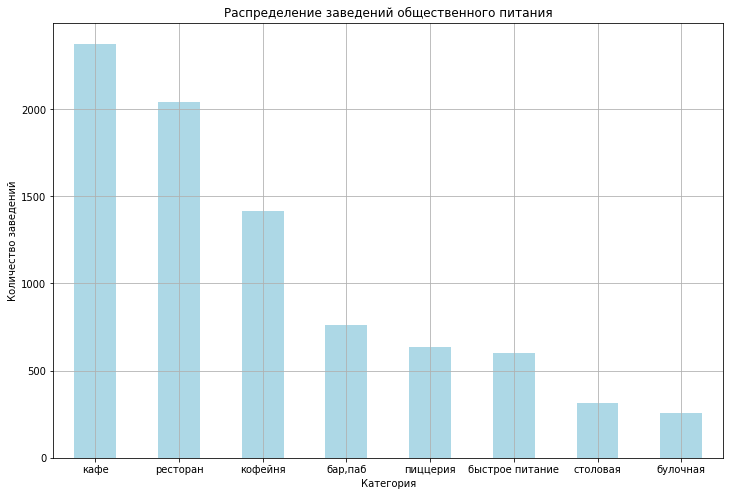

In [30]:
plt.figure(figsize=(12, 8))

# строим столбчатую диаграмму 
df['category'].value_counts().plot(
               kind='bar', 
               rot=0, # градус вращения подписи по оси Х
               legend=False, 
               title=f'Распределение заведений общественного питания',
               color='lightblue'
)


plt.ylabel('Количество заведений')
plt.xlabel('Категория')
# сетка
plt.grid()
plt.show()

Наибольшее количество забирают кафе, ресторы и кофейни. Далее идут Бар, паб, пиццерия и быстрое питане. Наименьшее количество у столовых и булочных, их открывают реже всего

---

### Задача 2

Какие административные районы Москвы присутствуют в данных? Исследуйте распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводите подходящими визуализациями.

In [31]:
# проверяем распределение данных по значениям столбца category
print('Распределение данных столбца district:')
df['district'].value_counts()

Распределение данных столбца district:


Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: district, dtype: int64

In [32]:
# проверяем распределение данных по значениям столбца category
print('Распределение данных столбца district:')
df['district'].value_counts(normalize=True)

Распределение данных столбца district:


Центральный административный округ         0.266841
Северный административный округ            0.106879
Южный административный округ               0.106165
Северо-Восточный административный округ    0.105927
Западный административный округ            0.101166
Восточный административный округ           0.094977
Юго-Восточный административный округ       0.084980
Юго-Западный административный округ        0.084385
Северо-Западный административный округ     0.048679
Name: district, dtype: float64

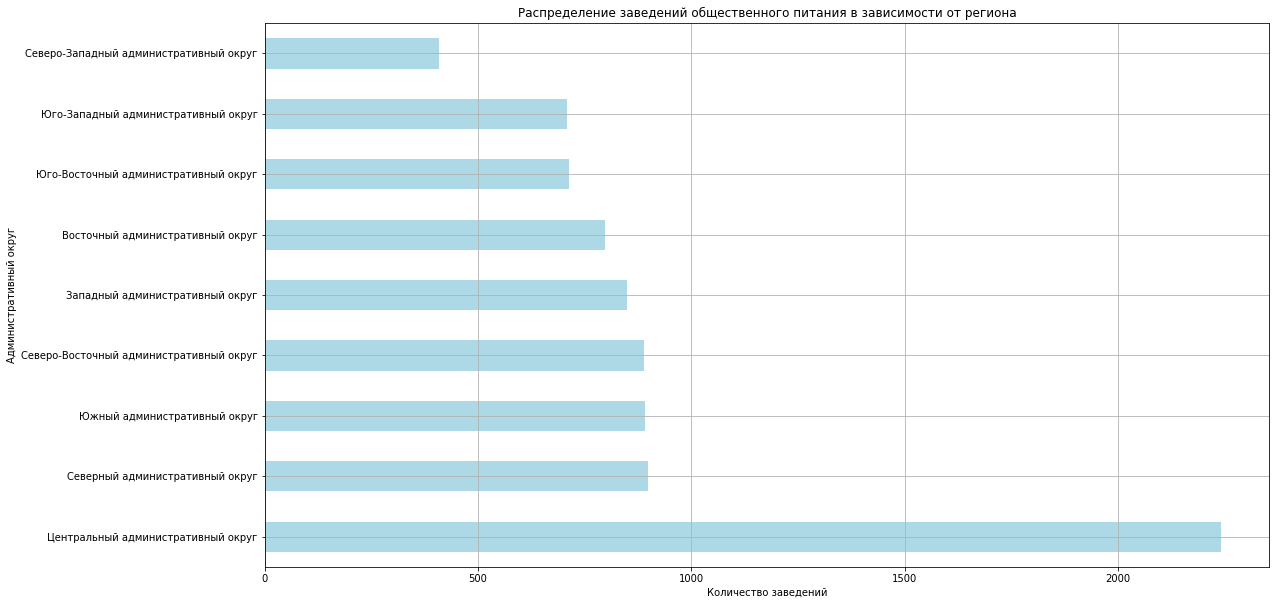

In [33]:
plt.figure(figsize=(18, 10))

df['district'].value_counts().plot(
               kind='barh',
               rot=0,
               legend=False,
               title='Распределение заведений общественного питания в зависимости от региона',
               color='lightblue'
)

plt.xlabel('Количество заведений')
plt.ylabel('Административный округ')
plt.grid()
plt.show()

Видим что больше всего заведений находится в ЦАО, остальные округа все примерно на одном уровне за исключением Северо-Западного

In [34]:
print('Распределение заведений в ЦАО:')
df[df['district'] == 'Центральный административный округ']['category'].value_counts()

Распределение заведений в ЦАО:


ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: category, dtype: int64

In [35]:
print('Распределение заведений в ЦАО:')
df[df['district'] == 'Центральный административный округ']['category'].value_counts(normalize=True)

Распределение заведений в ЦАО:


ресторан           0.298840
кафе               0.206958
кофейня            0.190901
бар,паб            0.162355
пиццерия           0.050401
быстрое питание    0.038805
столовая           0.029438
булочная           0.022302
Name: category, dtype: float64

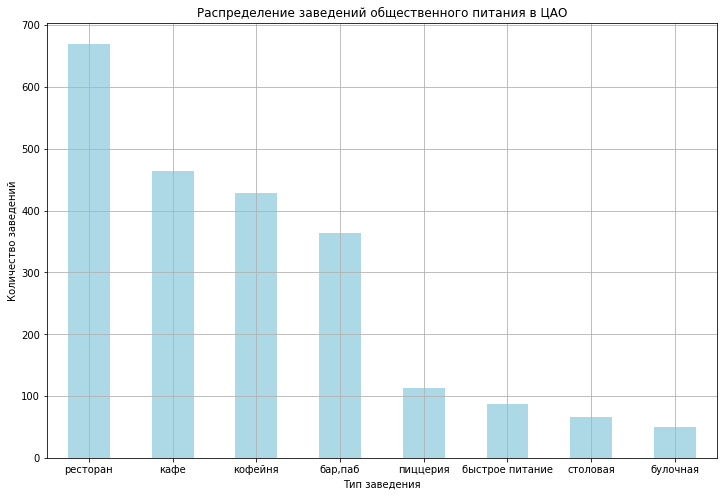

In [36]:
plt.figure(figsize=(12, 8))

df[df['district'] == 'Центральный административный округ']['category'].value_counts().plot(
               kind='bar',
               rot=0,
               legend=False,
               title='Распределение заведений общественного питания в ЦАО',
               color='lightblue'
)

plt.ylabel('Количество заведений')
plt.xlabel('Тип заведения')
plt.grid()
plt.show()

Наибольшее количество заведений сосредоточены в ЦАО, что говорит о том что люди чаще всего ходят поесть именно в этом округе (вероятно в связи с тем что многие работают/проводят досуг чаще в центре). Сильно преобладают ресторы, далее кафе, кофейни и бары, остальных заведений быстрого питания не так много 


---

### Задача 3

Изучите соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми? Исследуйте данные, ответьте на вопросы и постройте необходимые визуализации.

In [37]:
print('Распределение данных столбца district:')
df['chain'].value_counts()

Распределение данных столбца district:


0    5199
1    3203
Name: chain, dtype: Int64

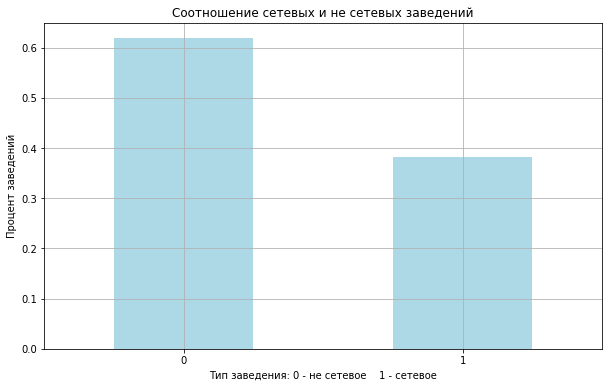

In [38]:
plt.figure(figsize=(10, 6))

df['chain'].value_counts(normalize=True).plot(
    kind='bar',
    rot=0,
    title='Соотношение сетевых и не сетевых заведений',
    color='lightblue'
)

plt.ylabel('Процент заведений')
plt.xlabel('Тип заведения: 0 - не сетевое    1 - сетевое')
plt.grid()
plt.show()

Не сетевых заведений больше, но не сильно

In [39]:
# сводная таблица: категории + сетевые/несетевые
pivot_table = pd.crosstab(
    index=df['category'], 
    columns=df['chain']
)

print(pivot_table)

chain               0    1
category                  
бар,паб           596  168
булочная           99  157
быстрое питание   371  232
кафе             1597  779
кофейня           693  720
пиццерия          303  330
ресторан         1313  729
столовая          227   88


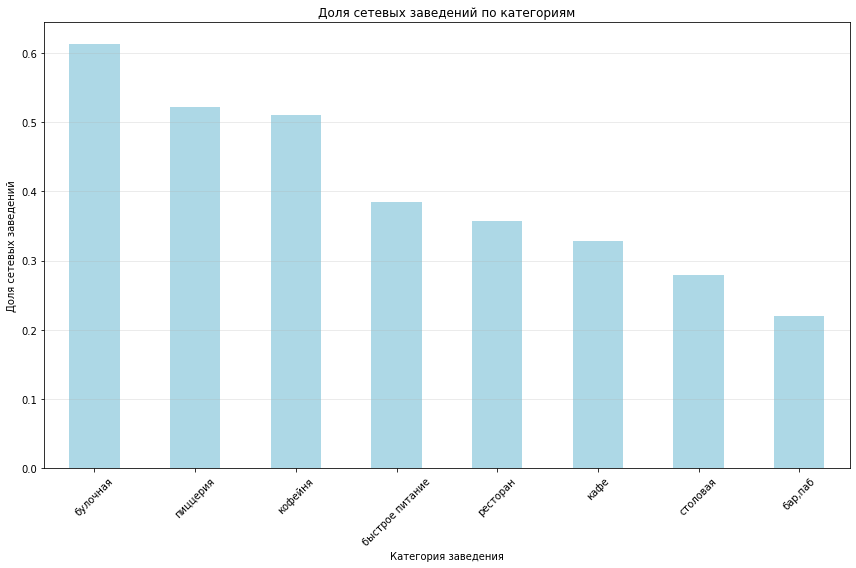

In [40]:
# Считаем долю сетевых заведений по категориям
proportion_chain = df.groupby('category')['chain'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 8))
proportion_chain.plot(
    kind='bar',
    color='lightblue'
)

plt.title('Доля сетевых заведений по категориям')
plt.ylabel('Доля сетевых заведений')
plt.xlabel('Категория заведения')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы:**

Cреди сетевых заведений чаще встречаются булочные, пиццерии и кофейни. Наименьшее количество сетевых заведений у баров, пабов и столовых

### Задача 4

Исследуйте количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Приведите для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводите подходящими визуализациями.


In [41]:
# для дальнейшего анализа будем использовать данные без индикаторов с пропусками
df = df.replace(-1, np.nan)
df.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 8402 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   id                 8402 non-null   object  
 1   name               8402 non-null   object  
 2   category           8402 non-null   category
 3   address            8402 non-null   object  
 4   district           8402 non-null   category
 5   hours              7867 non-null   object  
 6   rating             8402 non-null   float16 
 7   chain              8402 non-null   Int8    
 8   seats              4792 non-null   float16 
 9   price              3315 non-null   category
 10  avg_bill           3816 non-null   object  
 11  middle_avg_bill    3149 non-null   float16 
 12  middle_coffee_cup  535 non-null    float16 
 13  is_24_7            8402 non-null   bool    
dtypes: Int8(1), bool(1), category(3), float16(4), object(5)
memory usage: 509.6+ KB


In [42]:
df['seats'].describe()

count    4792.0
mean        inf
std         inf
min         0.0
25%        40.0
50%        75.0
75%       140.0
max      1288.0
Name: seats, dtype: float64

Максимальное значение слишком большое, скорее всего выброс либо ошибка в данных

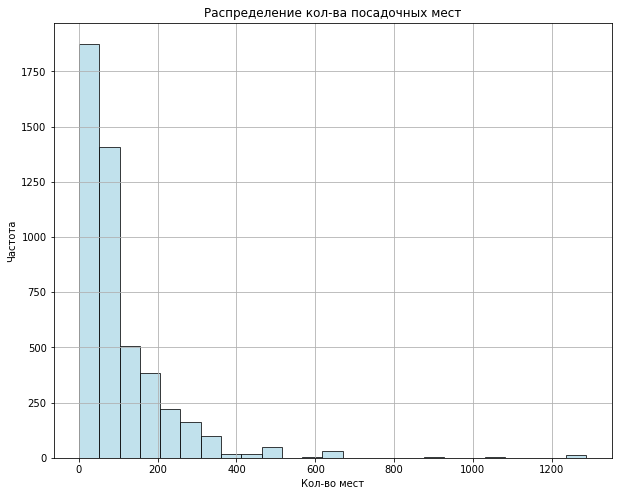

In [43]:
plt.figure(figsize=(10, 8))

# гистограмма
df['seats'].plot(
                kind='hist', 
                bins=25, # кол-во корзин
                alpha=0.75,
                edgecolor='black',
                rot=0, 
    color='lightblue'
)

plt.title('Распределение кол-ва посадочных мест')
plt.xlabel('Кол-во мест')
plt.ylabel('Частота')

plt.grid()

plt.show()

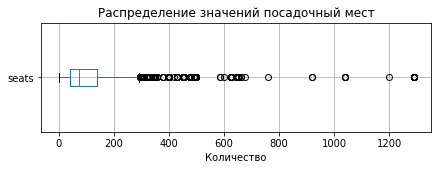

In [44]:
plt.figure(figsize=(7, 2))

# диаграмма размаха значений в столбце balance
df.boxplot(column='seats', vert=False)

plt.title('Распределение значений посадочный мест')
plt.xlabel('Количество')
plt.show()

Большое кол-во выбросов, скорее всего это общепит в торговых центрах, либо что-по подобное

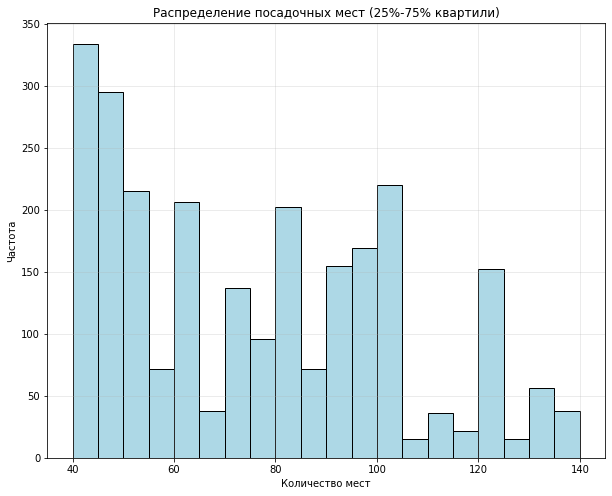

In [45]:
plt.figure(figsize=(10, 8))

# фильтруем данные: берем только между 1 и 3 квартилем, чтоб посмотреть наиболее типичные данные
q1 = df['seats'].quantile(0.25)
q3 = df['seats'].quantile(0.75)
filtered_data = df[(df['seats'] >= q1) & (df['seats'] <= q3)]

# строим гистограмму по столбцу 'seats'
plt.hist(filtered_data['seats'], bins=20, color='lightblue', edgecolor='black')

plt.title('Распределение посадочных мест (25%-75% квартили)')
plt.xlabel('Количество мест')
plt.ylabel('Частота')
plt.grid(True, alpha=0.3)
plt.show()

В целом похоже на правду, в каких-то заведениях предусмотрено небольшое кол-во мест, в других же наоборот

In [46]:
# группируем данные по категориям и вычисляем медиану (включая нули)
typical_seats = df.groupby('category')['seats'].median().sort_values(ascending=False)

print("Наиболее типичное количество посадочных мест по категориям (включая нулевые):")
print(typical_seats)

Наиболее типичное количество посадочных мест по категориям (включая нулевые):
category
ресторан           86.0
бар,паб            82.0
кофейня            80.0
столовая           75.5
быстрое питание    65.0
кафе               60.0
пиццерия           55.0
булочная           50.0
Name: seats, dtype: float16


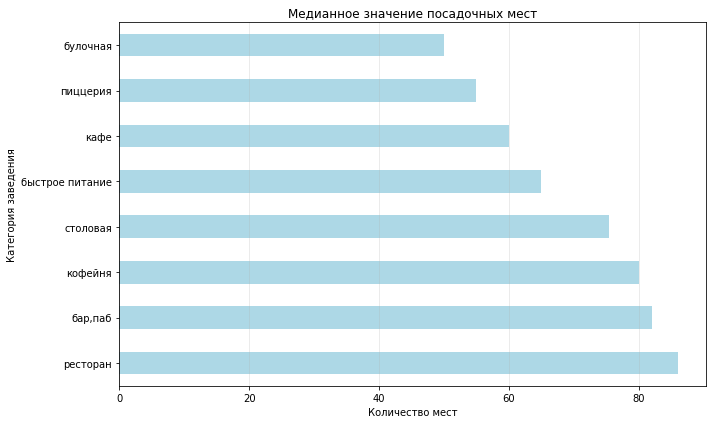

In [47]:
# диаграмма медиан (включая нули)
plt.figure(figsize=(10, 6))
typical_seats.plot(kind='barh',
                   color='lightblue'
)
plt.title('Медианное значение посадочных мест')
plt.xlabel('Количество мест')
plt.ylabel('Категория заведения')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод:**

Наибольшее медианное количество посадочных мест у ресторанов и баров/пабов, что соответствует их формату как заведений с полноценным обслуживанием. Средние значения у кофеен, столовых и предприятий быстрого питания. Наименьшие показатели у кафе, булочных и пиццерий где преобладает формат "еда на вынос" или минимальное количество мест

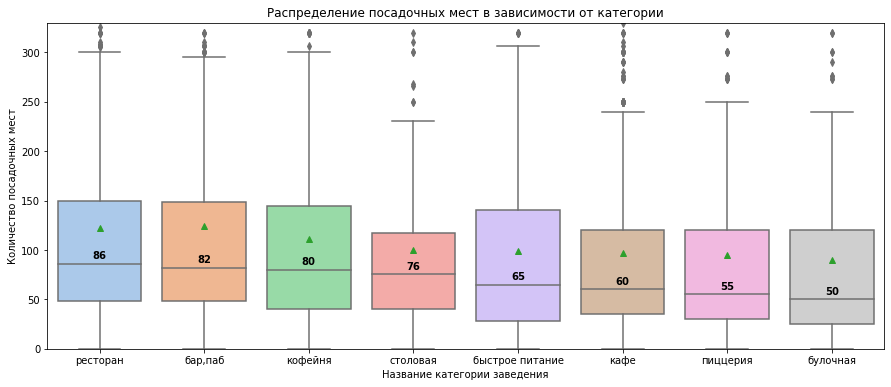

In [48]:
# Комментарий рев
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

tmp = df.copy()  # Создаем копию датасета, чтобы не работать с исходным

# Создаем список категорий сортированный по медианам
order = tmp.groupby('category')['seats'].median().sort_values(ascending=False).index 

# Рассчитываем медианы для каждой категории
medians = tmp.groupby('category')['seats'].median().sort_values(ascending=False)

# Построение диаграммы размаха с использованием seaborn
plt.figure(figsize=(15, 6))
ax = sns.boxplot(x='category', 
                y='seats', 
                data=tmp, 
                showmeans=True,  # Зеленые треугольники показывают среднее значение
                order=order,
                palette='pastel').set(title='Распределение посадочных мест в зависимости от категории', 
                             xlabel='Название категории заведения', 
                             ylabel='Количество посадочных мест',
                             ylim=(0, 330))

# Добавляем подписи медиан
for i, category in enumerate(order):
    median_val = medians[category]
    # Добавляем текст на позицию (x=i, y=median_val+5) для лучшей читаемости
    plt.text(i, median_val + 5, f'{median_val:.0f}', 
             horizontalalignment='center', 
             fontsize=10,
             color='black',
             weight='semibold')

# Отображение диаграммы
plt.show()

---

### Задача 5

Исследуйте рейтинг заведений. Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?

In [49]:
# вычисляем средние рейтинги по категориям
avg_ratings = df.groupby('category')['rating'].mean().sort_values(ascending=False)

print("Средние рейтинги по категориям заведений:")
print(avg_ratings)

Средние рейтинги по категориям заведений:
category
бар,паб            4.386719
пиццерия           4.300781
ресторан           4.289062
кофейня            4.277344
булочная           4.269531
столовая           4.210938
кафе               4.125000
быстрое питание    4.050781
Name: rating, dtype: float16


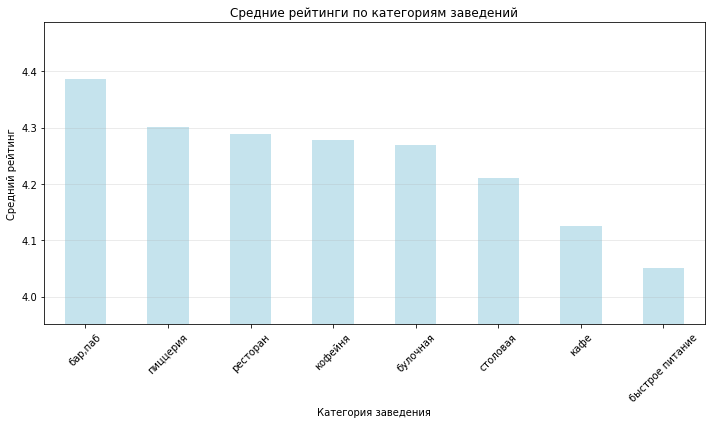

In [50]:
plt.figure(figsize=(10, 6))

avg_ratings.plot(kind='bar', 
                 color='lightblue', 
                 alpha=0.7)

plt.title('Средние рейтинги по категориям заведений')
plt.xlabel('Категория заведения')
plt.ylabel('Средний рейтинг')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.ylim(avg_ratings.min() - 0.1, avg_ratings.max() + 0.1)
plt.tight_layout()
plt.show()

**Вывод:**

Рейтинги всех категорий высокие (4 - 4,4). Пиццерии и рестораны лидируют, столовые и фастфуд немного отстают.

---

### Задача 6

Изучите, с какими данными показывают самую сильную корреляцию рейтинги заведений? Постройте и визуализируйте матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберите самую сильную связь и проверьте её.

In [51]:

# корр матрица
correlation_matrix = df[['district', 'category','chain', 'seats', 'price', 'is_24_7', 'rating']].phik_matrix()

print('Корреляционная матрица phi_k для rating')
correlation_with_rating = correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(
    by='rating', ascending=False
)
print(correlation_with_rating)

interval columns not set, guessing: ['chain', 'seats', 'rating']
Корреляционная матрица phi_k для rating
            rating
price     0.262893
district  0.200893
category  0.195451
is_24_7   0.161042
chain     0.121009
seats     0.000000


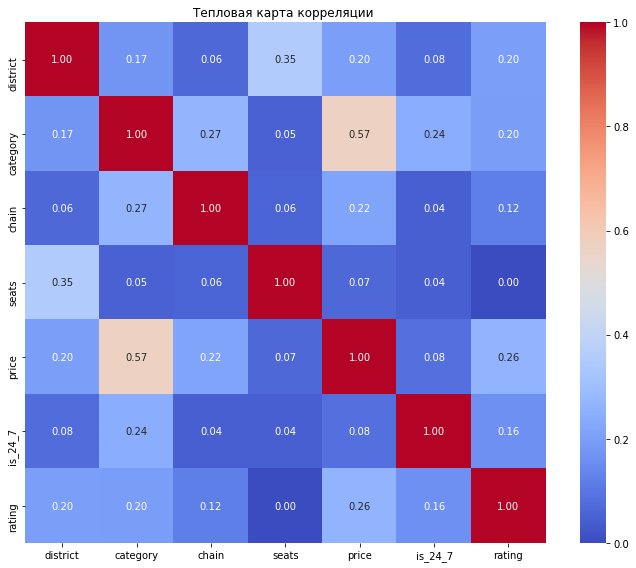

In [52]:

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,  # показывать значения в ячейках
    fmt=".2f",   # округление до 2 знаков после запятой
    cmap='coolwarm',  # цветовая схема
    square=True  #
)
plt.title('Тепловая карта корреляции ')
plt.tight_layout()
plt.show()

Наибольшая корреляция наблюдается у price, дальше идут district, category, is_24_7 примерно на одном уровне. У chain наблюдается маленькая корреляция. У seats - нулевая, это говорит о том, что количество посадочных мест никак не влияет на рейтинг заведения

In [53]:
# смотрим рейтинг заведений
print('Рейтинг заведения в зависимости от цены ')
avg_rating_by_price = df.groupby('price')['rating'].mean().sort_values()
print(avg_rating_by_price)

Рейтинг заведения в зависимости от цены 
price
низкие           4.171875
средние          4.296875
выше среднего    4.386719
высокие          4.437500
Name: rating, dtype: float16


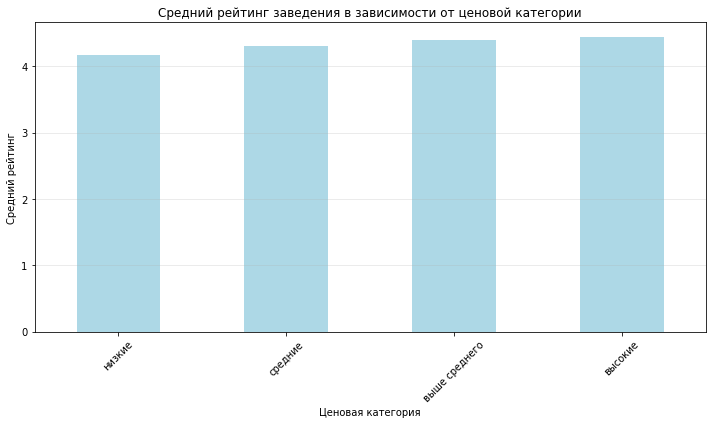

In [54]:

avg_rating_by_price.plot(
    kind='bar',
    title='Средний рейтинг заведения в зависимости от ценовой категории',
    ylabel='Средний рейтинг',
    xlabel='Ценовая категория',
    figsize=(10, 6),
    color='lightblue'
)

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Можно заметить что чем выше ценовая политика заведения тем выше рейтинг, наблюдается явная связь

### Задача 7

Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Для них посчитайте значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводите подходящими визуализациями.

In [55]:
# фильтруем только сетевые заведения
df_chain = df[df['chain'] == 1].copy()

# Группируем по названию сети
top_chains = (
    df_chain
    .groupby('name')
    .agg(
        count=('name', 'size'),
        avg_rating=('rating', 'mean')
    )
    .sort_values(by='count', ascending=False)
    .head(15)
)

# Выводим результат
print(top_chains)

                                     count  avg_rating
name                                                  
шоколадница                            120    4.179688
домино'с пицца                          76    4.171875
додо пицца                              74    4.285156
one price coffee                        71    4.066406
яндекс лавка                            69    3.873047
cofix                                   65    4.074219
prime                                   50    4.117188
хинкальная                              44    4.324219
кофепорт                                42    4.148438
кулинарная лавка братьев караваевых     39    4.394531
теремок                                 38    4.125000
чайхана                                 37    3.923828
cofefest                                32    3.984375
буханка                                 32    4.398438
му-му                                   27    4.230469


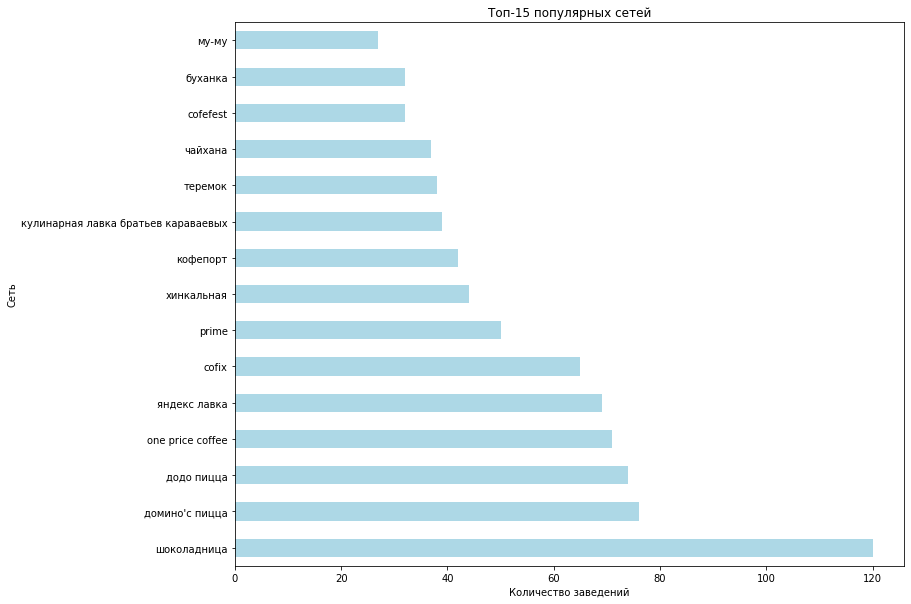

In [56]:
top_chains['count'].plot(
    kind='barh',
    title='Топ-15 популярных сетей',                 
    figsize=(12, 10),
    color='lightblue'
)
plt.xlabel('Количество заведений')
plt.ylabel('Сеть')
plt.show()

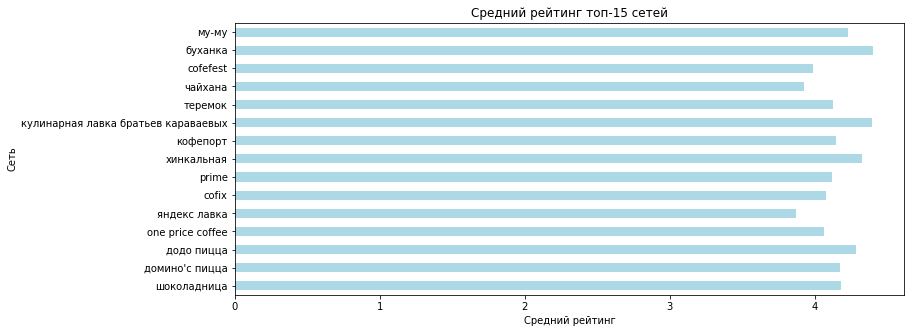

In [57]:
# средний рейтинг
top_chains['avg_rating'].plot(kind='barh', 
                                          title='Средний рейтинг топ-15 сетей', 
                                          figsize=(12, 5), 
                                          color='lightblue'
)
plt.xlabel('Средний рейтинг')
plt.ylabel('Сеть')
plt.show()

Видим что Шоколадница самая популярная сеть но при этом имеет не самый высокий рейтинг. Буханка, хинкальная и теремок имеют самые высокие рейниги не смотря на то что у них значительно меньше заведений чем у шоколадницы

### Задача 8

Изучите вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируйте цены в Центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях? Результат сопроводите подходящими визуализациями.


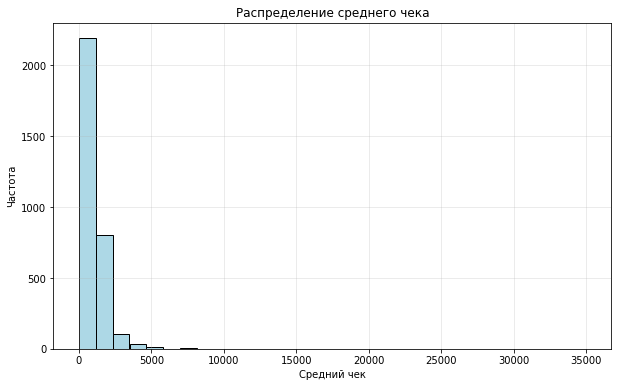

In [58]:
plt.figure(figsize=(10, 6))
plt.hist(df['middle_avg_bill'].dropna(), 
         bins=30, 
         color='lightblue', 
         edgecolor='black')

plt.title('Распределение среднего чека')
plt.xlabel('Средний чек')
plt.ylabel('Частота')
plt.grid(True, alpha=0.3)
plt.show()

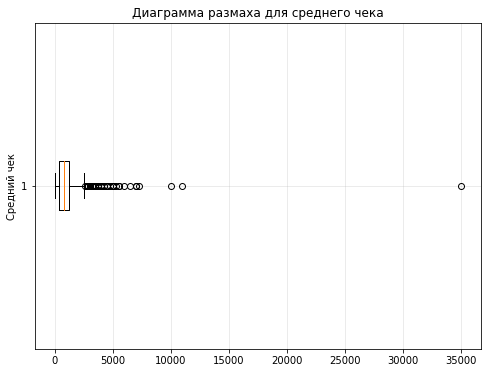

In [59]:
plt.figure(figsize=(8, 6))
plt.boxplot(df['middle_avg_bill'].dropna(), vert=False)

plt.title('Диаграмма размаха для среднего чека')
plt.ylabel('Средний чек')
plt.grid(True, alpha=0.3)
plt.show()

В среднем средний чек небольшой но присутствуют выбросы

In [60]:
avg_by_district = df.groupby('district')['middle_avg_bill'].agg(['mean', 'median']).sort_values(by='mean', ascending=False)

print(avg_by_district)

                                           mean  median
district                                               
Центральный административный округ       1191.0  1000.0
Западный административный округ          1053.0  1000.0
Северный административный округ           928.0   650.0
Южный административный округ              834.5   500.0
Северо-Западный административный округ    822.0   700.0
Восточный административный округ          820.5   575.0
Юго-Западный административный округ       792.5   600.0
Северо-Восточный административный округ   716.5   500.0
Юго-Восточный административный округ      654.0   450.0


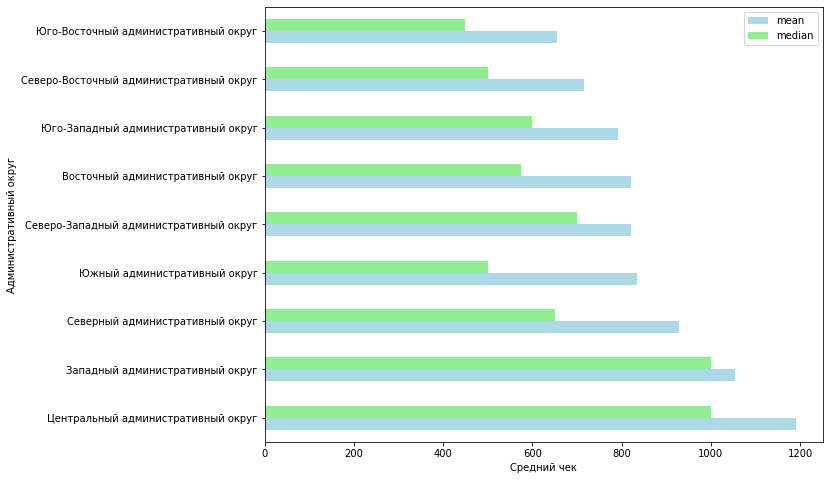

In [61]:
# построим диаграмму среднего чека
avg_by_district.head(10).plot(
    kind='barh',
    figsize=(10, 8), 
    color=['lightblue','lightgreen']
)

plt.xlabel('Средний чек')
plt.ylabel('Административный округ')
plt.show()

Самый высокий средний чек - в Центральном административном округе. Среднее значение здесь превышает 1100 рублей, что является абсолютным максимумом по всем округам. Медиана также самая высокая - около 1000 рублей. Это можно объяснить тем, что ЦАО - деловой, туристический и культурный центр Москвы. Здесь сосредоточены офисы, театры, музеи, отели и элитные жк. Потребительская аудитория - бизнесмены, туристы, состоятельные жители - готова платить больше за комфорт, сервис и имидж. Заведения в ЦАО часто позиционируются как премиальные, с высокими ценами на аренду, персонал и продукты.


Разрыв между средним и медианой во многих округах (особенно в ЦАО, ЗАО, ЮАО) говорит о наличии выбросов в сторону высоких цен - то есть в каждом округе есть несколько заведений с очень высоким чеком, которые "тянут" среднее вверх. Центральный и Западный округа - лидеры по среднему чеку, но при этом имеют наибольшую дисперсию, что подтверждает наличие премиальных и бюджетных заведений в одном районе. Юго-Восточный и Северо-Восточный округа - самые «бюджетные», с низкими медианными значениями и меньшей разницей между средним и медианой, что говорит о более однородной ценовой политике.


ЦАО - лидер по среднему чеку, что обусловлено его статусом делового и туристического центра. Северо-Западный и Северный округа - самые стабильные по ценам, без резких выбросов. Юго-Восточный округ - самый бюджетный, что соответствует его демографическому и экономическому профилю. Разница между средним и медианой - ключевой индикатор наличия премиальных заведений, влияющих на общую картину. Этот анализ позволяет инвесторам выбрать целевой округ для открытия заведения в зависимости от их стратегии: премиум (ЦАО/ЗАО) или массовый сегмент (ЮВАО/СВАО).



---

### Промежуточный вывод

Обобщите полученные результаты, выделив, по вашему мнению, самые важные.

Рынок насыщен, но не закрыт 
Кафе и рестораны лидируют по количеству заведений, но есть пространство для нишевых форматов. Булочные, столовые, фастфуд в спальных районах менее конкурентны

ЦАО доминирует по трафику но и по издержкам. Центральный округ дорогой и переполнен конкуренцией. Юго-Западный, Южный и Северо-Западный округа дешевле и стабильнее для входа

Сетевые заведения занимают 40% рынка особенно в кафе и кофейнях, но популярность не гарантирует высокий рейтинг

Шоколадница крупнейшая но не самая рейтинговая, Буханка наоборот маленькая, но с высоким рейтингом

Высокий рейтинг важнее популярности клиенты доверяют отзывам 
Бары и пабы лидируют по рейтингу, быстрое питание отстаёт 

Цены зависят от локации, в центре выше, в периферийных районах ниже, что открывает возможности для бизнеса с меньшими затратами


## 4. Итоговый вывод и рекомендации

По результатам проведённого исследовательского анализа данных сформулируйте итоговый вывод и рекомендации для заказчика. Старайтесь акцентировать внимание на ключевых моментах исследования.

При составлении вывода придерживайтесь такой структуры:

1. Общий обзор проделанной работы.
2. Ответы на исследовательские вопросы, или главные выводы.
3. Рекомендации на основе анализа данных.

**Были выполнены следующие действия**

1. Загрузка данных и знакомство с их содержимым
2. Предобработка данных
3. Проведён исследовательский анализ данных 
4. Выявлены зависимости
5. Сформулированны выводы и рекомндации

**Общие выводы**

Лидируют кафе и рестораны (по 2000 заведений), за ними - кофейни. Центральный административный округ доминирует по количеству точек (более 2000), что говорит о высоком спросе но и о жёсткой конкуренции. Сетевые заведения составляют около 40% рынка - особенно сильны в кафе, ресторанах и кофейнях, тогда как булочные и столовые почти полностью несетевые

Средние рейтинги показывают: самые высокие - у баров/пабов  и пиццерий, а самые низкие - у быстрого питания. При этом популярность сети не всегда коррелирует с рейтингом: например, «Шоколадница» - самая крупная сеть (120 заведений), но её рейтинг ниже среднего, тогда как «Буханка», хоть и мала по числу точек, имеет самый высокий рейтинг среди топ-15 сетей

Цены выше всего в центре города - чем дальше от ЦАО, тем ниже средний чек, что открывает возможности для бизнеса в периферийных районах с меньшими затратами

**Рекомендации**

Для успешного входа в рынок общепита стоит выбирать форматы с меньшей конкуренцией - булочные или столовые, особенно в спальных районах, где конкуренция ниже, а спрос на доступную еду стабилен (учитывая бюджет)

При этом локация остаётся ключевым фактором: если позволяет бюджет, можно рассмотреть Центральный административный округ, где высокий трафик, но если нет - Северо-Западный или Южный округа тоже подойдут

Начинать лучше с несетевого формата, чтобы гибко тестировать и масштабировать бизнес позже. Важно понимать, что высокий рейтинг заведения влияет на доверие клиентов больше, чем количество точек, поэтому качество обслуживания и продуктов должно быть в приоритете